In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El responsable de la organización de un congreso científico ha descrito así las actividades y sus dependencias:

> Definición del programa y fechas (A) puede empezar desde el principio. Para empezar Contratación de ponentes invitados (E) hace falta haber terminado Definición del programa y fechas (A), Reserva de la sede (B) y Convocatoria de comunicaciones (C). Una vez terminadas Definición del programa y fechas (A), Reserva de la sede (B) y Convocatoria de comunicaciones (C), puede empezar Página web e inscripciones (D). Para empezar Edición del libro de actas (I) hace falta haber terminado Revisión de los trabajos recibidos (F). Reserva de la sede (B) puede empezar desde el principio. Una vez terminada Contratación de ponentes invitados (E), puede empezar Revisión de los trabajos recibidos (F). Elaboración del programa definitivo (G) sigue a Página web e inscripciones (D) y Contratación de ponentes invitados (E). Contratación de catering y viajes (H) sigue a Elaboración del programa definitivo (G). Convocatoria de comunicaciones (C) puede empezar desde el principio.

In [3]:
pregunta_1 = "1. Construya el cuadro de prelaciones inmediatas a partir del texto (una fila por actividad con sus predecesoras inmediatas).  "
pregunta_2 = "2. Construya el cuadro de prelaciones expandido e indique las actividades iniciales y finales.  "
pregunta_3 = "3. Construya el cuadro de ancestros y compruebe que ninguna prelación del texto es redundante.  "
pregunta_4 = "4. Dibuje el grafo PERT con el mínimo número de ficticias.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Construya el cuadro de prelaciones inmediatas a partir del texto (una fila por actividad con sus predecesoras inmediatas).  

2. Construya el cuadro de prelaciones expandido e indique las actividades iniciales y finales.  

3. Construya el cuadro de ancestros y compruebe que ninguna prelación del texto es redundante.  

4. Dibuje el grafo PERT con el mínimo número de ficticias.  

# Resolución

## Apartado 1

In [4]:
display(Markdown(pregunta_1))

1. Construya el cuadro de prelaciones inmediatas a partir del texto (una fila por actividad con sus predecesoras inmediatas).  

Se recorre el texto actividad por actividad anotando sólo las predecesoras que el texto nombra de forma explícita; las que se deducen por transitividad no se anotan.

In [5]:
#| tbl-cap: "Cuadro de prelaciones inmediatas"
#| label: tbl-prelaciones
datos_enunciado = pd.DataFrame([
#  activity, predecessor
    ('A'     , '---'      ),
    ('B'     , '---'      ),
    ('C'     , '---'      ),
    ('D'     , 'A,B,C'    ),
    ('E'     , 'A,B,C'    ),
    ('F'     , 'E'        ),
    ('G'     , 'D,E'      ),
    ('H'     , 'G'        ),
    ('I'     , 'F'        ),
], columns=['activity', 'predecessor']).set_index('activity')
datos_enunciado

,predecessor
activity,
A,---
B,---
C,---
D,"A,B,C"
E,"A,B,C"
F,E
G,"D,E"
H,G
I,F


In [6]:
descripciones = pd.Series({
    'A': 'Definición del programa y fechas',
    'B': 'Reserva de la sede',
    'C': 'Convocatoria de comunicaciones',
    'D': 'Página web e inscripciones',
    'E': 'Contratación de ponentes invitados',
    'F': 'Revisión de los trabajos recibidos',
    'G': 'Elaboración del programa definitivo',
    'H': 'Contratación de catering y viajes',
    'I': 'Edición del libro de actas',
}, name='Descripción')
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 2

In [7]:
display(Markdown(pregunta_2))

2. Construya el cuadro de prelaciones expandido e indique las actividades iniciales y finales.  

In [8]:
#| tbl-cap: "Cuadro de prelaciones expandido"
#| label: tbl-prelacionesExpandido
prelaciones.display_immediate_linkage_matrix()

,A,B,C,D,E,F,G,H,I
activities,,,,,,,,,
A,,,,,,,,,
B,,,,,,,,,
C,,,,,,,,,
D,True,True,True,,,,,,
E,True,True,True,,,,,,
F,,,,,True,,,,
G,,,,True,True,,,,
H,,,,,,,True,,
I,,,,,,True,,,


In [9]:
print('Actividades iniciales:', ', '.join(sorted(prelaciones.start_activities)))
print('Actividades finales:  ', ', '.join(sorted(prelaciones.end_activities)))

Actividades iniciales: A, B, C
Actividades finales:   H, I


## Apartado 3

In [10]:
display(Markdown(pregunta_3))

3. Construya el cuadro de ancestros y compruebe que ninguna prelación del texto es redundante.  

In [11]:
#| tbl-cap: "Cuadro de ancestros"
#| label: tbl-ancestros
proyecto.distant_predecessor(format='DataFrame')

,predecessors
A,----
B,----
C,----
D,"A, B, C"
E,"A, B, C"
F,"A, B, C, E"
G,"A, B, C, D, E"
H,"A, B, C, D, E, G"
I,"A, B, C, E, F"


In [12]:
G = nx.DiGraph([(p, a) for a, ps in prelaciones.immediate_predecessor.items() for p in ps])
G.add_nodes_from(datos_proyecto.index)
redundantes = sorted(set(G.edges) - set(nx.transitive_reduction(G).edges))
print('Prelaciones redundantes:', redundantes or 'ninguna')

Prelaciones redundantes: ninguna


## Apartado 4

In [13]:
display(Markdown(pregunta_4))

4. Dibuje el grafo PERT con el mínimo número de ficticias.  

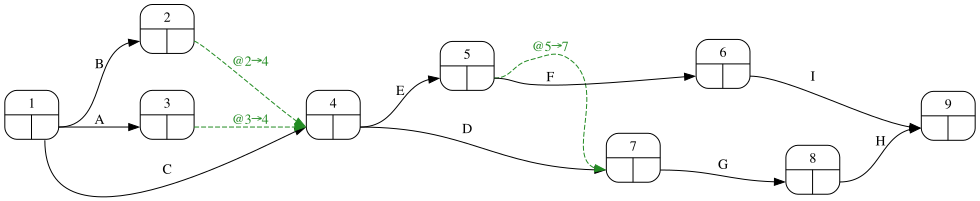

In [14]:
#| fig-cap: "Grafo PERT del proyecto"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)